# Projet 7 – Étape 3 : Clustering non supervisé

**Objectif :** Regrouper les images sans utiliser les labels,  
puis vérifier si ces groupes correspondent aux classes cancer/normal.

**Pipeline :**
1. Charger les features produites à l'étape 2
2. Réduire la dimension avec **PCA** (2048 → 50)
3. Visualiser en 2D avec **t-SNE**
4. Clustériser avec **K-Means**
5. Évaluer avec le score **ARI**

⚠️ Les données labelisées et sans label restent strictement séparées.

## 0. Imports et chargement des features

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"    #pour éviter un warning de scikit-learn sur Windows

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

# Chemin vers les features sauvegardées à l'étape 2
DIR_OUTPUT = Path(".") / "output"   # output de l'étape 2

# Chargement
features_label   = np.load(DIR_OUTPUT / "features_label.npy")
features_unlabel = np.load(DIR_OUTPUT / "features_unlabel.npy")
labels           = np.load(DIR_OUTPUT / "labels.npy")

print(f"Features labelisées  : {features_label.shape}")
print(f"Features sans label  : {features_unlabel.shape}")
print(f"Labels               : {labels.shape} — valeurs : {np.unique(labels)}")

Features labelisées  : (100, 2048)
Features sans label  : (1406, 2048)
Labels               : (100,) — valeurs : [0 1]


## 1. Normalisation

Avant PCA et K-Means, on normalise les features —  
chaque colonne aura une moyenne de 0 et un écart-type de 1.  
Sans ça, les features avec de grandes valeurs domineraient les calculs de distance.

In [2]:
scaler = StandardScaler()

# IMPORTANT : on fit le scaler sur les données sans label (la plus grande),
# puis on applique la même transformation aux deux jeux.
# On ne mélange pas les données — on utilise juste les mêmes paramètres de normalisation.
scaler.fit(features_unlabel)

features_label_scaled   = scaler.transform(features_label)
features_unlabel_scaled = scaler.transform(features_unlabel)

print("Normalisation appliquée.")
print(f"Moyenne features labelisées après normalisation : {features_label_scaled.mean():.4f}")

Normalisation appliquée.
Moyenne features labelisées après normalisation : -0.0624


## 2. Réduction de dimension avec PCA

On passe de 2048 à 100 dimensions en gardant l'essentiel de la variance.

In [3]:
N_COMPOSANTES = 100

pca = PCA(n_components=N_COMPOSANTES, random_state=42)

# Même logique : on fit sur les données sans label
pca.fit(features_unlabel_scaled)

features_label_pca   = pca.transform(features_label_scaled)
features_unlabel_pca = pca.transform(features_unlabel_scaled)

# Quelle part de la variance totale est conservée ?
variance_conservee = pca.explained_variance_ratio_.sum() * 100

print(f"Shape après PCA (labelisé)  : {features_label_pca.shape}")
print(f"Shape après PCA (sans label): {features_unlabel_pca.shape}")
print(f"Variance conservée          : {variance_conservee:.1f}%")

Shape après PCA (labelisé)  : (100, 100)
Shape après PCA (sans label): (1406, 100)
Variance conservée          : 58.8%


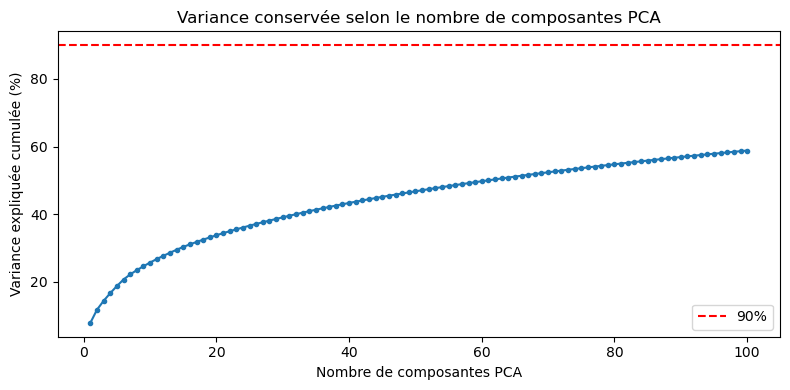

In [4]:
# Courbe de variance expliquée cumulée
variance_cumulee = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, N_COMPOSANTES+1), variance_cumulee, marker="o", markersize=3)
plt.axhline(y=90, color="red", linestyle="--", label="90%")
plt.xlabel("Nombre de composantes PCA")
plt.ylabel("Variance expliquée cumulée (%)")
plt.title("Variance conservée selon le nombre de composantes PCA")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Visualisation avec t-SNE

t-SNE réduit encore plus (100 → 2 dimensions) pour pouvoir afficher les images  
sur un graphique 2D. C'est uniquement pour la visualisation, pas pour le clustering.

On applique t-SNE sur les données labelisées pour voir si cancer et normal  
forment des groupes distincts.

In [5]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
features_label_2d = tsne.fit_transform(features_label_pca)

print(f"Shape t-SNE : {features_label_2d.shape}")

Shape t-SNE : (100, 2)


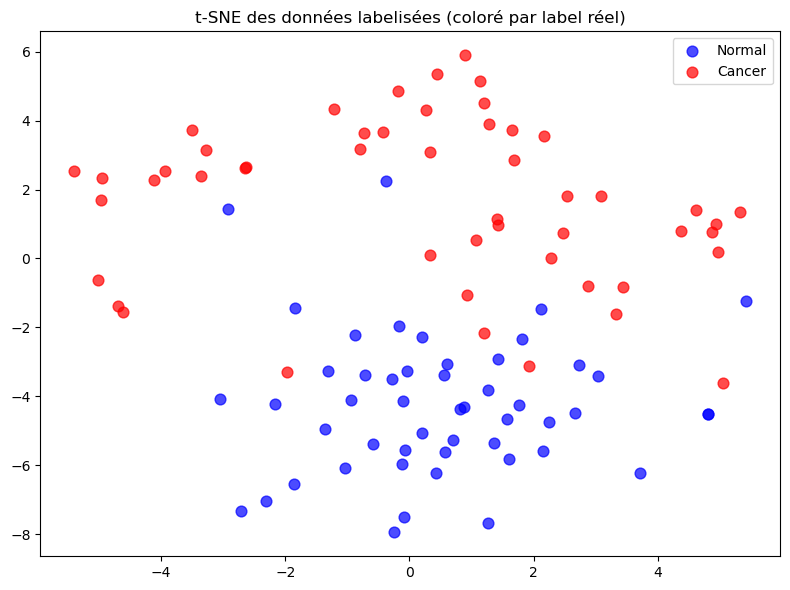

In [6]:
# Visualisation t-SNE colorée par label réel
couleurs = ["blue" if l == 0 else "red" for l in labels]

plt.figure(figsize=(8, 6))
for label_val, couleur, nom in [(0, "blue", "Normal"), (1, "red", "Cancer")]:
    masque = labels == label_val
    plt.scatter(
        features_label_2d[masque, 0],
        features_label_2d[masque, 1],
        c=couleur, label=nom, alpha=0.7, s=60
    )

plt.title("t-SNE des données labelisées (coloré par label réel)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Clustering K-Means

On applique K-Means sur les données **sans label** (PCA).  
On cherche 2 clusters — comme il y a 2 classes dans le dataset labelisé.

In [7]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(features_unlabel_pca)

clusters_unlabel = kmeans.labels_     # resultat du clustering sur les données sans label

print(f"Clusters trouvés : {np.unique(clusters_unlabel)}")
print(f"Distribution     : {dict(zip(*np.unique(clusters_unlabel, return_counts=True)))}")

Clusters trouvés : [0 1]
Distribution     : {np.int32(0): np.int64(795), np.int32(1): np.int64(611)}


In [8]:
# On applique aussi K-Means sur les données labelisées pour pouvoir calculer l'ARI
clusters_label = kmeans.predict(features_label_pca)

print(f"Clusters prédits sur données labelisées : {dict(zip(*np.unique(clusters_label, return_counts=True)))}")

Clusters prédits sur données labelisées : {np.int32(0): np.int64(71), np.int32(1): np.int64(29)}


## 5. Évaluation avec le score ARI

L'ARI (Adjusted Rand Index) compare les clusters trouvés avec les vrais labels.  
- ARI = 1.0 → clustering parfait  
- ARI = 0.0 → clustering aléatoire  
- ARI < 0  → pire que le hasard

On calcule l'ARI **uniquement sur les données labelisées** — c'est la seule façon  
de comparer clusters et vrais labels sans tricher.

In [9]:
ari = adjusted_rand_score(labels, clusters_label)
print(f"Score ARI : {ari:.4f}")

if ari > 0.5:
    print("→ Bon clustering : les groupes correspondent bien aux classes réelles.")
elif ari > 0.2:
    print("→ Clustering partiel : une certaine correspondance mais imparfaite.")
else:
    print("→ Clustering faible : les groupes ne correspondent pas bien aux classes.")

Score ARI : 0.2437
→ Clustering partiel : une certaine correspondance mais imparfaite.


## 6. Visualisation des clusters sur t-SNE

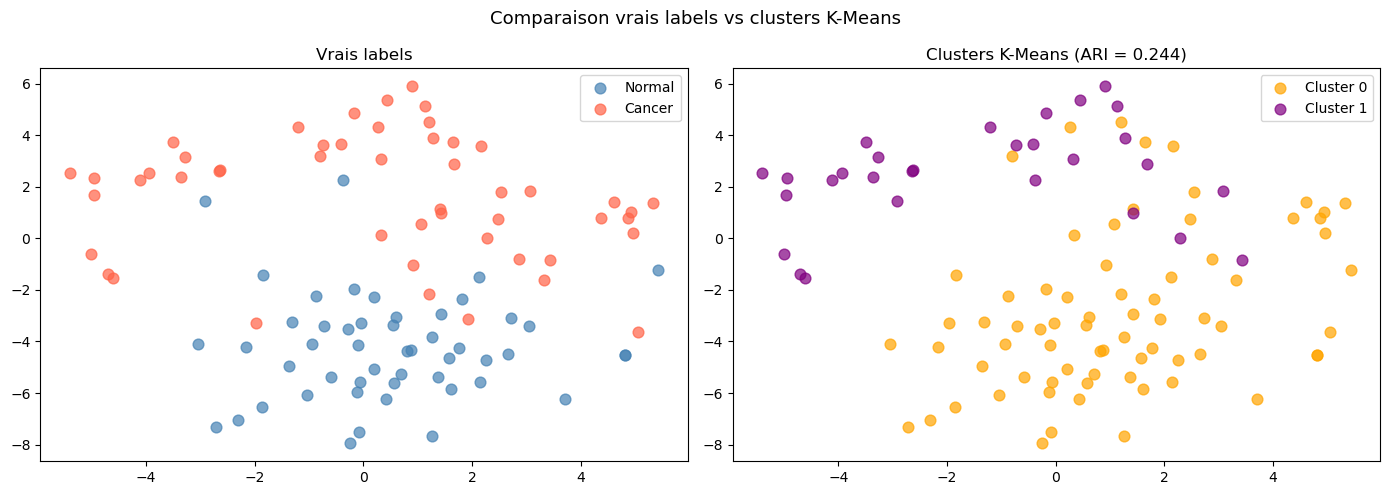

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gauche : coloré par vrais labels
for label_val, couleur, nom in [(0, "steelblue", "Normal"), (1, "tomato", "Cancer")]:
    masque = labels == label_val
    axes[0].scatter(features_label_2d[masque, 0], features_label_2d[masque, 1],
                    c=couleur, label=nom, alpha=0.7, s=60)
axes[0].set_title("Vrais labels")
axes[0].legend()

# Droite : coloré par clusters K-Means
for cluster_val, couleur, nom in [(0, "orange", "Cluster 0"), (1, "purple", "Cluster 1")]:
    masque = clusters_label == cluster_val
    axes[1].scatter(features_label_2d[masque, 0], features_label_2d[masque, 1],
                    c=couleur, label=nom, alpha=0.7, s=60)
axes[1].set_title(f"Clusters K-Means (ARI = {ari:.3f})")
axes[1].legend()

plt.suptitle("Comparaison vrais labels vs clusters K-Means", fontsize=13)
plt.tight_layout()
plt.show()

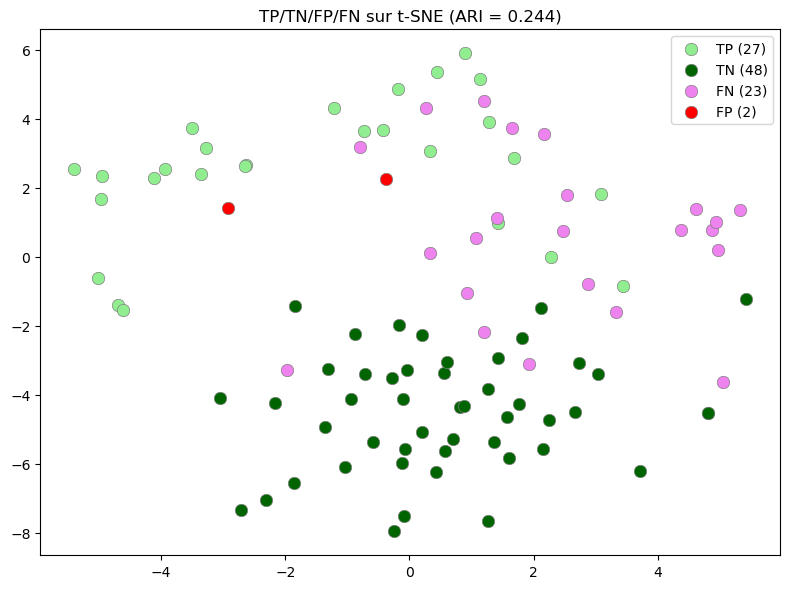

In [11]:
# Correspondance clusters → labels (K-Means numérote arbitrairement)
# On vérifie quel cluster correspond le mieux à cancer (1)
from scipy.stats import mode
mapping = {}
for cluster in [0, 1]:
    masque = clusters_label == cluster
    label_dominant = mode(labels[masque]).mode
    mapping[cluster] = label_dominant

# Si le mapping est inversé, on retourne les clusters
clusters_label_mapped = np.where(clusters_label == list(mapping.keys())[list(mapping.values()).index(1)], 1, 0)

# Calcul TP, TN, FP, FN
couleurs_detail = []
for vrai, predit in zip(labels, clusters_label_mapped):
    if vrai == 1 and predit == 1:   couleurs_detail.append(("lightgreen", "TP (cancer bien classé)"))
    elif vrai == 0 and predit == 0: couleurs_detail.append(("darkgreen", "TN (normal bien classé)"))
    elif vrai == 1 and predit == 0: couleurs_detail.append(("violet", "FN (cancer manqué)"))
    else:                           couleurs_detail.append(("red", "FP (normal classé cancer)"))

couleurs = [c[0] for c in couleurs_detail]

# Plot
plt.figure(figsize=(8, 6))
for couleur, label_txt in [("lightgreen", "TP"), ("darkgreen", "TN"), ("violet", "FN"), ("red", "FP")]:
    masque = [i for i, c in enumerate(couleurs_detail) if c[0] == couleur]
    plt.scatter(features_label_2d[masque, 0], features_label_2d[masque, 1],
                c=couleur, label=f"{label_txt} ({len(masque)})", s=80, edgecolors="gray", linewidths=0.5)

plt.title(f"TP/TN/FP/FN sur t-SNE (ARI = {ari:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

## 6bis. Clustering DBSCAN (comparaison)

Contrairement à K-Means, DBSCAN ne demande pas de fixer le nombre de clusters —
il les déduit de la densité des points, et peut classer certains points comme **bruit** (label `-1`).

En contrepartie il faut choisir deux paramètres :
- `eps` : distance max entre deux points pour être "voisins"
- `min_samples` : nb de voisins minimum pour former une zone dense

On travaille sur `features_label_pca` (comme pour K-Means) afin de pouvoir comparer aux vrais labels via l'ARI.

### 6bis.1 Choix de `eps` — graphique des k-distances

Méthode classique : pour chaque point, on calcule la distance à son k-ième plus proche voisin
(k = `min_samples`), on trie ces distances, et on cherche le "coude" de la courbe.
Ce coude donne une bonne valeur de départ pour `eps`.

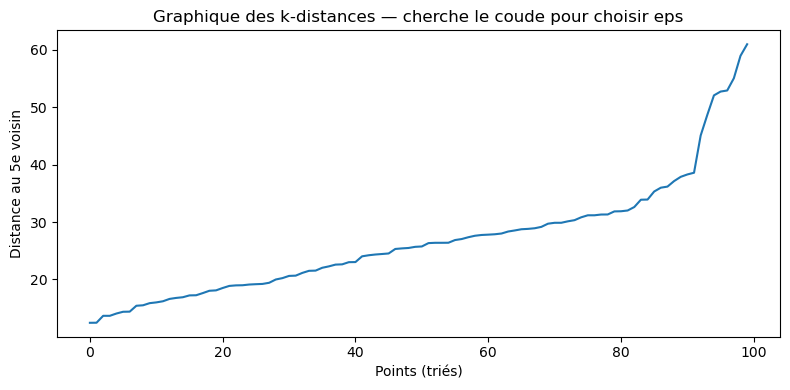

Distance médiane : 25.72
Voir distance au coude approximative (à ajuster à l'oeil) sur le graphique ci-dessus.


In [28]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 5

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbors.fit(features_label_pca)
distances, _ = neighbors.kneighbors(features_label_pca)

# Distance au k-ième voisin, triée par ordre croissant
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Points (triés)")
plt.ylabel(f"Distance au {MIN_SAMPLES}e voisin")
plt.title("Graphique des k-distances — cherche le coude pour choisir eps")
plt.tight_layout()
plt.show()

print(f"Distance médiane : {np.median(k_distances):.2f}")
print(f"Voir distance au coude approximative (à ajuster à l'oeil) sur le graphique ci-dessus.")

### 6bis.2 Entraînement DBSCAN + score ARI

Ajuste `EPS` en fonction du coude observé ci-dessus, puis relance la cellule si besoin.

In [13]:
EPS = 38  # <-- à ajuster selon le coude du graphique précédent

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
clusters_dbscan_label = dbscan.fit_predict(features_label_pca)

n_clusters = len(set(clusters_dbscan_label)) - (1 if -1 in clusters_dbscan_label else 0)
n_bruit = list(clusters_dbscan_label).count(-1)

print(f"Nombre de clusters trouvés : {n_clusters}")
print(f"Points classés comme bruit (-1) : {n_bruit} / {len(clusters_dbscan_label)}")
print(f"Distribution : {dict(zip(*np.unique(clusters_dbscan_label, return_counts=True)))}")

# ARI : on garde tous les points (le bruit -1 est traité comme un cluster à part entière par le score)
ari_dbscan = adjusted_rand_score(labels, clusters_dbscan_label)
print(f"\nScore ARI (DBSCAN) : {ari_dbscan:.4f}")
print(f"Score ARI (K-Means): {ari:.4f}")

Nombre de clusters trouvés : 1
Points classés comme bruit (-1) : 6 / 100
Distribution : {np.int64(-1): np.int64(6), np.int64(0): np.int64(94)}

Score ARI (DBSCAN) : 0.0041
Score ARI (K-Means): 0.2437


Scrore ARI pour DBSCAN avec EPS=38 => 0.004 (Mauvais)  
=> Tuning d'hyperparamaetres (minsamples et eps) 

In [ ]:
for minsamples_test in [3, 4, 5, 6, 7]:
    print()
    print(f"*************** Min_sample={minsamples_test} ***************")
    for eps_test in [18, 20, 22, 24, 26, 28, 30, 32, 34, 38]:
        db = DBSCAN(eps=eps_test, min_samples=minsamples_test)
        cl = db.fit_predict(features_label_pca)
        ari_test = adjusted_rand_score(labels, cl)
        n_bruit = list(cl).count(-1)
        n_clust = len(set(cl)) - (1 if -1 in cl else 0)
        print(f"eps={eps_test:2d} | clusters={n_clust} | bruit={n_bruit:3d} | ARI={ari_test:.4f}")



*************** Min_sample=3 ***************
eps=18 | clusters=1 | bruit= 72 | ARI=0.2644
eps=20 | clusters=2 | bruit= 58 | ARI=0.4459
eps=22 | clusters=1 | bruit= 54 | ARI=0.4036
eps=24 | clusters=3 | bruit= 41 | ARI=0.3272
eps=26 | clusters=1 | bruit= 28 | ARI=0.0950
eps=28 | clusters=1 | bruit= 23 | ARI=0.0415
eps=30 | clusters=1 | bruit= 15 | ARI=0.0049
eps=32 | clusters=1 | bruit= 14 | ARI=0.0096
eps=34 | clusters=1 | bruit= 10 | ARI=0.0028

*************** Min_sample=4 ***************
eps=18 | clusters=1 | bruit= 72 | ARI=0.2644
eps=20 | clusters=1 | bruit= 63 | ARI=0.4302
eps=22 | clusters=1 | bruit= 54 | ARI=0.4036
eps=24 | clusters=2 | bruit= 46 | ARI=0.3727
eps=26 | clusters=1 | bruit= 29 | ARI=0.1082
eps=28 | clusters=1 | bruit= 23 | ARI=0.0415
eps=30 | clusters=1 | bruit= 16 | ARI=0.0090
eps=32 | clusters=1 | bruit= 14 | ARI=0.0096
eps=34 | clusters=1 | bruit= 10 | ARI=0.0028

*************** Min_sample=5 ***************
eps=18 | clusters=1 | bruit= 73 | ARI=0.2859
eps=20 

In [26]:
dbscan = DBSCAN(eps=22, min_samples=5)
clusters_dbscan_label = dbscan.fit_predict(features_label_pca)
ari_dbscan = adjusted_rand_score(labels, clusters_dbscan_label)

### 6bis.3 Comparaison visuelle : vrais labels vs K-Means vs DBSCAN

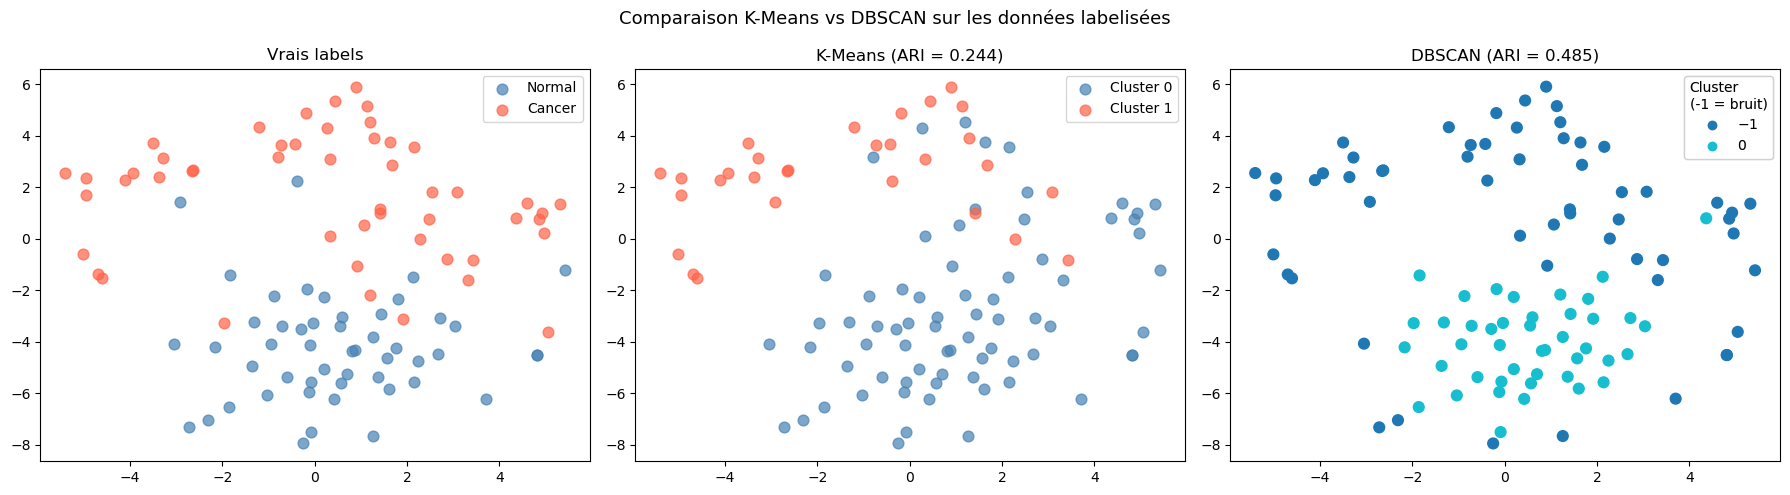

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# --- Vrais labels ---
for label_val, couleur, nom in [(0, "steelblue", "Normal"), (1, "tomato", "Cancer")]:
    masque = labels == label_val
    axs[0].scatter(features_label_2d[masque, 0], features_label_2d[masque, 1],
                   c=couleur, label=nom, alpha=0.7, s=60)
axs[0].set_title("Vrais labels")
axs[0].legend()

# --- K-Means ---
for cluster_val, couleur, nom in [(0, "steelblue", "Cluster 0"), (1, "tomato", "Cluster 1")]:
    masque = clusters_label == cluster_val
    axs[1].scatter(features_label_2d[masque, 0], features_label_2d[masque, 1],
                   c=couleur, label=nom, alpha=0.7, s=60)
axs[1].set_title(f"K-Means (ARI = {ari:.3f})")
axs[1].legend()

# --- DBSCAN ---
scatter = axs[2].scatter(features_label_2d[:, 0], features_label_2d[:, 1],
                          c=clusters_dbscan_label, cmap="tab10", s=60)
axs[2].set_title(f"DBSCAN (ARI = {ari_dbscan:.3f})")
legend2 = axs[2].legend(*scatter.legend_elements(), title="Cluster\n(-1 = bruit)")
axs[2].add_artist(legend2)

plt.suptitle("Comparaison K-Means vs DBSCAN sur les données labelisées", fontsize=13)
plt.tight_layout()
plt.show()

**Lecture rapide :**
DBSCAN avec eps=22 et min_samples=5 obtient un meilleur score ARI que K-Means (0.485 vs 0.244) mais au prix de 57% des points classés comme bruit (-1)
il isole juste un sous-groupe dense de Normal, mais pas vraiment de faire apparaitre un vrai cluster Cancer. 
K-Means, lui, couvre 100% des points avec une séparation plus grossière mais globale. Le gain d'ARI de DBSCAN est donc trompeur car il ne peut pas trancher sur plus de la moitié des cas.

## 7. Sauvegarde des clusters

On sauvegarde les clusters des données sans label —  
ce sont les **labels faibles** qu'on utilisera à l'étape 4.

In [18]:
np.save(DIR_OUTPUT / "clusters_unlabel.npy", clusters_unlabel)

meta_unlabel = pd.read_csv(DIR_OUTPUT / "meta_unlabel.csv")
meta_unlabel["cluster"] = clusters_unlabel
meta_unlabel.to_csv(DIR_OUTPUT / "meta_unlabel_clusters.csv", index=False)

print("Clusters sauvegardés.")
print(meta_unlabel.head(10).to_string(index=False))

Clusters sauvegardés.
                                 fichier  cluster
001b158a-7af8-451e-bf31-3a9116265f3a.jpg        1
00366e8d-5520-4d3c-a70b-91a7eec1f521.jpg        0
00455a62-f79f-4072-9a23-4951e759acdc.jpg        0
004ce5f5-ca6b-490f-9b2f-c322c152e2ee.jpg        0
005d9a37-8894-4eb5-8367-1015d4a43638.jpg        1
009e9d31-9f37-4d97-a941-81501294c403.jpg        1
009eac4a-c951-4da9-852a-b32e9ce20c6e.jpg        1
00e9e198-79de-47ab-9f4e-7b76152324bb.jpg        1
01274f5e-3064-4efd-af4b-38e164188c31.jpg        1
01717fbf-4bcf-475a-a718-361ed07d2854.jpg        1


## 8. Bilan

| Étape | Résultat |
|---|---|
| PCA 100 composantes | % variance conservée : 58.8% |
| t-SNE visualisation | pas mal |
| K-Means (k=2) | Score ARI : 0.2437 |
| Interprétation | TP 27, TN 48, FN 23, FP 2  |
| DBSCAN (eps=?, min_samples=5) | Score ARI : à compléter après ajustement de eps |

In [16]:
np.save(DIR_OUTPUT / "tsne_label_2d.npy", features_label_2d)